# Motorcycle detection and tracking with YOLO

**Goal:** learn how YOLO tracking behaves on the selected CCTV clip, compare two built-in trackers, and inspect results visually before writing application code.

> A tracker ID is only a temporary identity within one video run.

## Imports and experiment settings

Change the paths and class ID below. For a COCO-pretrained YOLO model, motorcycle is class `3`.

In [8]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

VIDEO_PATH = Path('../data/raw/video.mp4')
MODEL_PATH = Path('yolo12n.pt')
OUTPUT_DIR = Path('outputs')
CLASS_ID = 3  # COCO motorcycle
TRACKER = "bytetrack.yaml"                           # compare "botsort.yaml", and "bytetrack.yaml"
CONFIDENCE = 0.20
IMAGE_SIZE = 960
FRAME_STRIDE = 1                                   # keep 1 for crossing-time work
DEVICE = "cpu"                                     # use index number (e.g. 0) if compatible GPU available
MAX_FRAMES = None                                  # e.g. 500 for a quick experiment

assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
assert MODEL_PATH.exists(), f"Model weights not found: {MODEL_PATH}"
print("Video:", VIDEO_PATH)
print("Weights:", MODEL_PATH)
print("Tracker:", TRACKER)

Video: ..\data\raw\video.mp4
Weights: yolo12n.pt
Tracker: bytetrack.yaml


## Inspect the video before tracking

Display a few frames at different timestamps. Check whether motorcycles are large enough to detect and whether they overlap or disappear behind other vehicles.

In [9]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps

print(f"{width}x{height} | {fps:.2f} FPS | {duration:.1f} seconds | {frame_count} frames")

2568x1440 | 30.00 FPS | 31.7 seconds | 950 frames


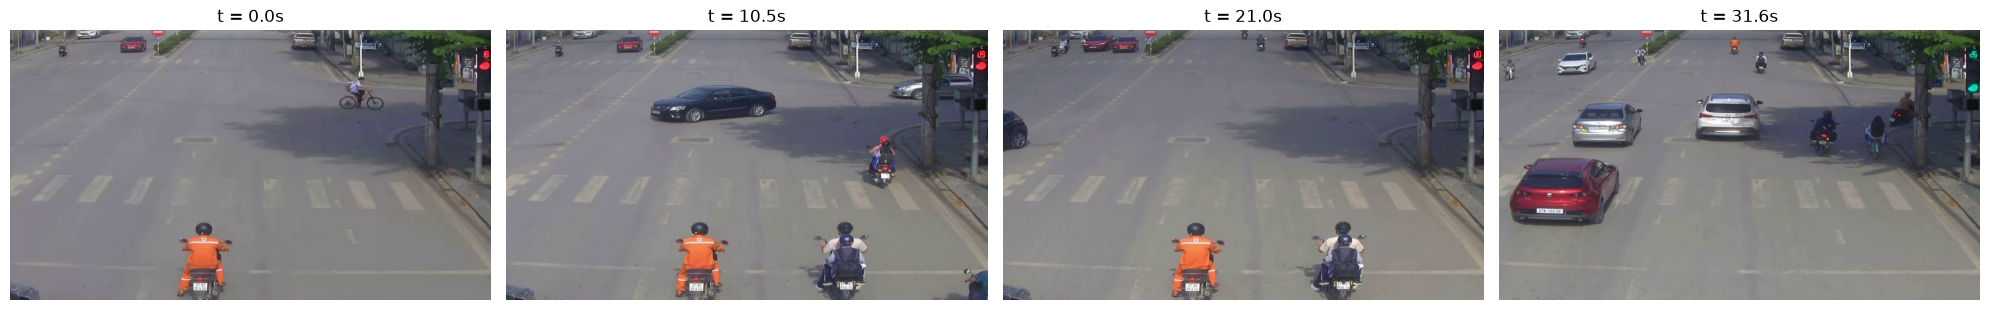

In [10]:
sample_times = np.linspace(0, max(0, duration - 0.1), min(4, max(1, int(duration))))

fig, axes = plt.subplots(1, len(sample_times), figsize=(5 * len(sample_times), 4))
if len(sample_times) == 1: axes = [axes]

for ax, seconds in zip(axes, sample_times):
    cap.set(cv2.CAP_PROP_POS_MSEC, float(seconds * 1000))
    ok, frame = cap.read()
    
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"t = {seconds:.1f}s")
    
    ax.axis("off")

plt.tight_layout()
cap.release()

## Run YOLO built-in tracking

`persist=True` tells Ultralytics that each frame belongs to the same video sequence, so it can maintain track state between calls. Use a new model instance and start at the first frame when repeat an experiment.

In [11]:
model = YOLO(str(MODEL_PATH))
cap = cv2.VideoCapture(str(VIDEO_PATH))
rows = []
frame_index = 0

while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES is not None and frame_index >= MAX_FRAMES):
        break
    
    if frame_index % FRAME_STRIDE == 0:
        result = model.track(
            frame,
            persist=True,
            tracker=TRACKER,
            conf=CONFIDENCE,
            imgsz=IMAGE_SIZE,
            classes=[CLASS_ID],
            device=DEVICE,
            verbose=False,
        )[0]
        boxes = result.boxes
        if boxes is not None and boxes.id is not None:
            ids = boxes.id.int().cpu().tolist()
            xyxys = boxes.xyxy.cpu().numpy()
            scores = boxes.conf.cpu().numpy()
            for track_id, box, score in zip(ids, xyxys, scores):
                x1, y1, x2, y2 = map(float, box)
                rows.append({"frame": frame_index, "time_sec": frame_index / fps,
                             "track_id": int(track_id), "x1": x1, "y1": y1,
                             "x2": x2, "y2": y2, "confidence": float(score),
                             "center_x": (x1 + x2) / 2, "center_y": (y1 + y2) / 2})
    frame_index += 1
cap.release()
tracks = pd.DataFrame(rows)

print(f"Processed {frame_index} frames; collected {len(tracks)} track observations.")

if not tracks.empty:
    display(tracks.head())
else:
    print("No track IDs returned. Check model path, class ID, confidence and video quality.")

Processed 950 frames; collected 6036 track observations.


,frame,time_sec,track_id,x1,y1,x2,y2,confidence,center_x,center_y
0,0,0.000000,1,894.135986,1083.506836,1185.200684,1440.000000,0.453244,1039.668335,1261.753418
1,0,0.000000,2,257.383820,62.162018,313.064606,142.227509,0.398691,285.224213,102.194763
2,1,0.033333,1,897.636169,1088.008423,1185.058228,1440.000000,0.429413,1041.347198,1264.004211
3,1,0.033333,2,258.372650,65.270470,311.731934,141.903061,0.425369,285.052292,103.586765
4,2,0.066667,1,897.134827,1086.746948,1185.575195,1440.000000,0.431080,1041.355011,1263.373474


## Visualize tracks over time

The first plot shows each track's centre point over the image plane. The second shows how long each ID remains visible. Use these plots to spot abrupt jumps, very short fragments and suspicious ID changes.

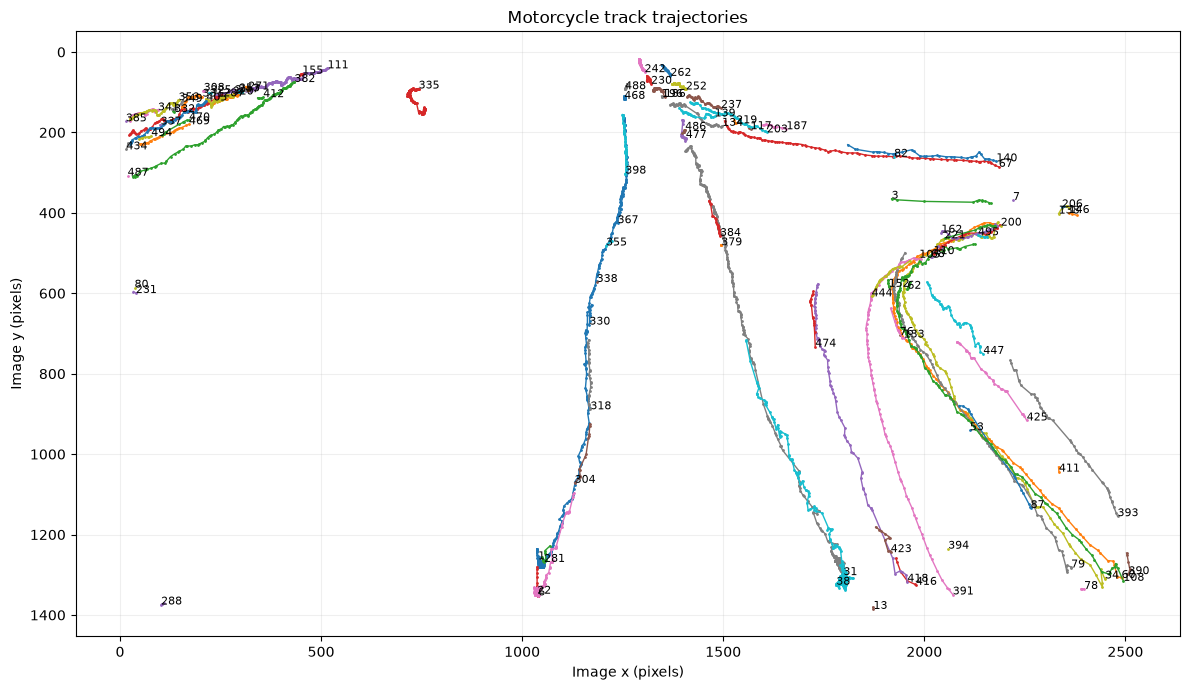

,first_frame,last_frame,observations,mean_confidence,duration_sec
track_id,,,,,
1,0,911,856,0.412390,30.400000
2,0,730,731,0.434707,24.366667
31,251,921,612,0.441250,22.366667
38,262,765,476,0.395739,16.800000
22,230,710,457,0.505854,16.033333
111,437,773,332,0.378042,11.233333
335,778,949,155,0.406618,5.733333
34,258,408,149,0.518011,5.033333
6,23,233,145,0.498016,7.033333


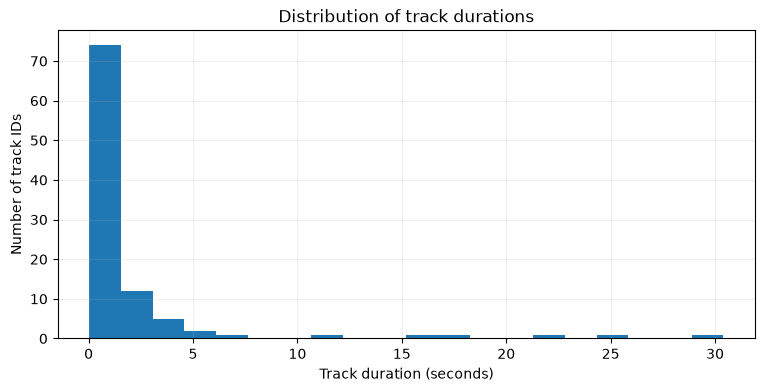

In [12]:
if not tracks.empty:
    plt.figure(figsize=(12, 7))
    
    for track_id, group in tracks.groupby("track_id"):
        plt.plot(group.center_x, group.center_y, marker=".", markersize=2, linewidth=1, label=f"ID {track_id}")
        first = group.iloc[0]
        plt.text(first.center_x, first.center_y, str(track_id), fontsize=8)
    
    plt.gca().invert_yaxis()
    plt.xlabel("Image x (pixels)"); plt.ylabel("Image y (pixels)")
    plt.title("Motorcycle track trajectories")
    
    if tracks.track_id.nunique() <= 15: plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    
    plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

    summary = tracks.groupby("track_id").agg(
        first_frame=("frame", "min"), last_frame=("frame", "max"),
        observations=("frame", "count"), mean_confidence=("confidence", "mean")
    )
    summary["duration_sec"] = (summary.last_frame - summary.first_frame + 1) / fps
    
    display(summary.sort_values("observations", ascending=False).head(20))
    
    plt.figure(figsize=(9, 4))
    plt.hist(summary.duration_sec, bins=20)
    plt.xlabel("Track duration (seconds)")
    plt.ylabel("Number of track IDs")
    plt.title("Distribution of track durations")
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("Run the tracking cell first and check that tracks were detected.")

## Draw boxes and track IDs on selected video frames

These visual checks are useful for understanding what the tracker is doing. Look at busy frames where motorcycles overlap, pass close together or are partly hidden.

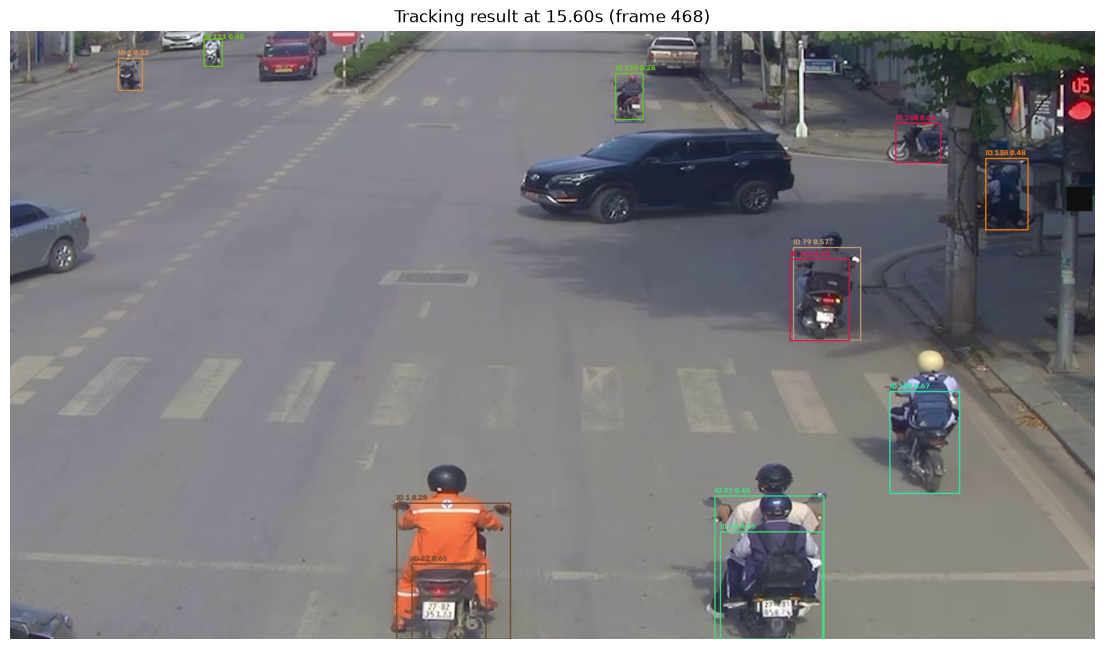

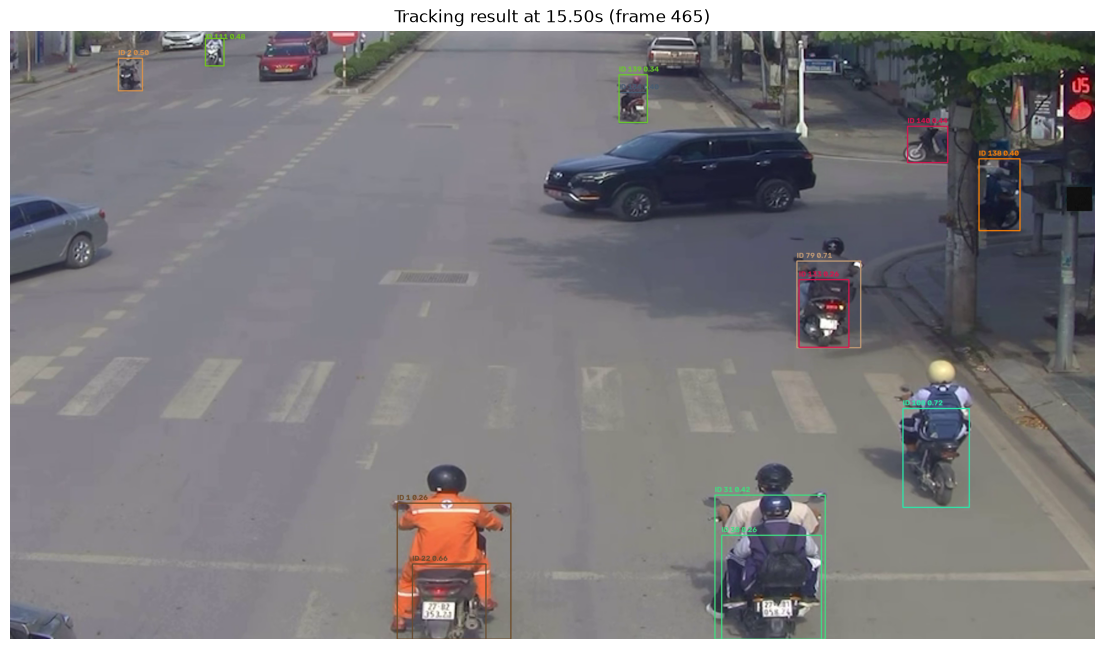

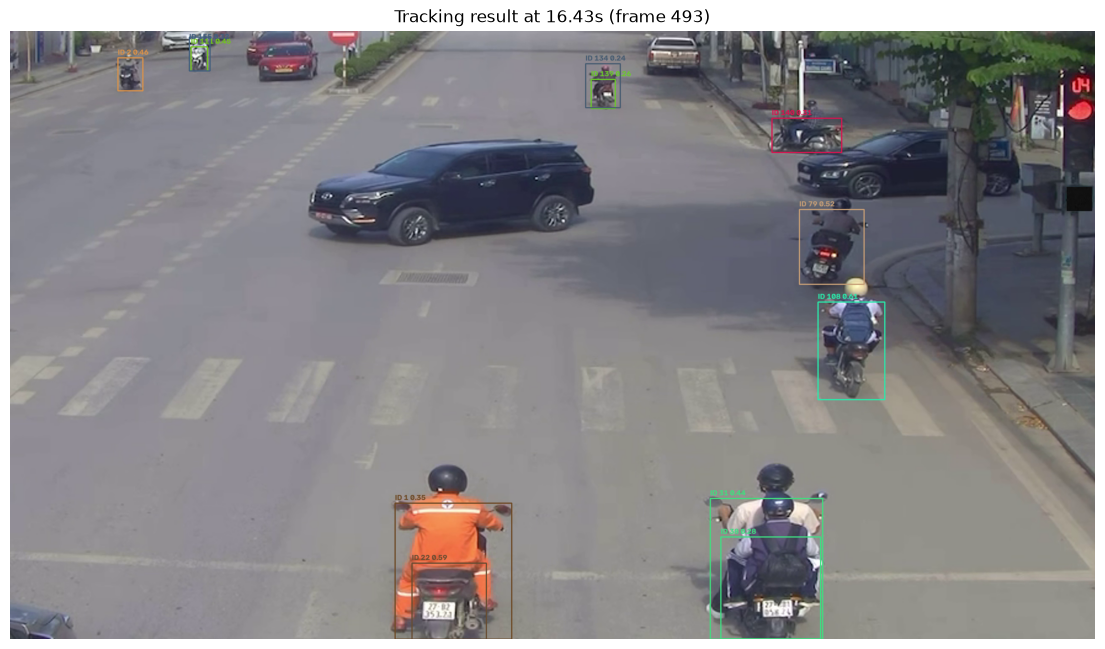

In [13]:
def show_tracking_frame(video_path, observations, seconds, fps_value):
    cap = cv2.VideoCapture(str(video_path))
    frame_no = int(seconds * fps_value)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no)
    ok, frame = cap.read(); cap.release()
    
    if not ok:
        print("Could not read frame", frame_no)
        return
    
    selected = observations[observations.frame == frame_no]
    for row in selected.itertuples():
        x1, y1, x2, y2 = map(int, [row.x1, row.y1, row.x2, row.y2])
        color = (int((row.track_id * 37) % 255), int((row.track_id * 73) % 255), int((row.track_id * 109) % 255))
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        cv2.putText(frame, f"ID {row.track_id} {row.confidence:.2f}", (x1, max(20, y1 - 7)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Tracking result at {seconds:.2f}s (frame {frame_no})")
    plt.axis("off"); plt.show()

if not tracks.empty:
    interesting_frames = tracks.groupby("frame").size().sort_values(ascending=False).head(3).index.tolist()
    for frame_no in interesting_frames:
        show_tracking_frame(VIDEO_PATH, tracks, frame_no / fps, fps)

## Save experimental results

Keep experiment outputs separate from source code. The CSV can be used later to compare settings or manually inspect ID changes.

In [14]:
OUTPUT_DIR.mkdir(exist_ok=True)

if not tracks.empty:
    output_csv = OUTPUT_DIR / f"tracks_{TRACKER.replace('.yaml', '')}.csv"
    tracks.to_csv(output_csv, index=False)
    print("Saved:", output_csv.resolve())
else:
    print("No observations to save.")

Saved: C:\Users\Pasidu\OneDrive\Documents\Developments\AI\Projects\Assignments\motosignal-ai\notebooks\outputs\tracks_bytetrack.csv



# Experiment Summary and Conclusion

## Experiment Overview

- **BoT-SORT**
- **ByteTrack**

Both trackers were tested using the same video, YOLO detection model, and general detection settings. The purpose was to understand how each tracker assigns and maintains object IDs across consecutive video frames.

## Experimental Results

The generated CSV files were analysed to compare the tracking outputs.

| Evaluation Metric | ByteTrack | BoT-SORT |
|---|---:|---:|
| Total tracked observations | 6,036 | 6,055 |
| Unique track IDs | 100 | 101 |
| Average tracked observations per frame | 6.35 | 6.37 |
| Average detection confidence | 0.441 | 0.440 |
| Median observations per track ID | 13 | 10 |
| Track IDs with only one observation | 10 | 18 |
| Track IDs with at least 10 observations | 55 | 51 |
| Observations in the longest-lived track | 856 | 743 |

The video segment represented in the CSV files contains 950 frames, covering approximately 31.63 seconds.

## Observations

### ByteTrack

- Produced slightly fewer unique track IDs than BoT-SORT.
- Had fewer track IDs with only one observation.
- Maintained longer observation sequences for some objects.
- Produced a longer-lasting main track in this experiment.

### BoT-SORT

- Produced slightly more tracked observations overall.
- Generated a similar average detection confidence.
- Produced more track IDs that appeared only once.
- Also maintained several long observation sequences.

### Comparison

Both trackers produced similar overall detection outputs. However, ByteTrack showed better results in some simple track-continuity indicators, particularly the number of short-lived IDs and the number of observations associated with longer tracks.

These results are preliminary observations from one video, not a definitive accuracy benchmark.

## Conclusion and Decision

Both BoT-SORT and ByteTrack can be used as candidate tracking algorithms for the MotoSignal AI project.

Based on the current CSV statistics, **ByteTrack is selected as the initial candidate for further development**, because it produced fewer single-observation track IDs and maintained longer observation sequences in this particular video.